In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def _sample_directions(self, n: int) -> np.ndarray:
        """Вспомогательный метод: разыгрывает n случайных направлений."""
        phi = np.random.uniform(0, 2 * np.pi, size=n)
        cos_theta = np.random.uniform(-1.0, 1.0, size=n)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        
        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta
        return np.column_stack((nx, ny, nz))

    def generate_photons_single(self, E: float):
        """
        Генератор (вариант 1): возвращает (yield) по 1 фотону за раз.
        Общее число фотонов распределено по Пуассону со средним E * Y.
        """
        N = np.random.poisson(lam=self.Y * E)
        for _ in range(N):
            # Генерируем 1 направление и берем 0-ю строку, чтобы вернуть вектор (nx, ny, nz)
            yield self._sample_directions(1)[0]

    def generate_photons_batch(self, E: float, batch_size: int = 100):
        """
        Генератор (вариант 2): возвращает (yield) пачками по 100 фотонов.
        Общее число фотонов распределено по Пуассону со средним E * Y.
        """
        N = np.random.poisson(lam=self.Y * E)
        
        # Идем от 0 до N с шагом batch_size (0, 100, 200, ...)
        for i in range(0, N, batch_size):
            # Для последней пачки берем остаток (N - i), если он меньше 100
            current_size = min(batch_size, N - i)
            yield self._sample_directions(current_size)

Первые 2 фотона из поштучного генератора:
[ 0.80960545  0.58374552 -0.06148315]
[-0.63055554 -0.76464189 -0.13312589]

Событие E = 1 МэВ:
Всего выдано пачек: 100
Размер первой пачки: (100, 3)
Размер последней пачки (остаток): (47, 3)
Суммарное число фотонов в событии: 9947


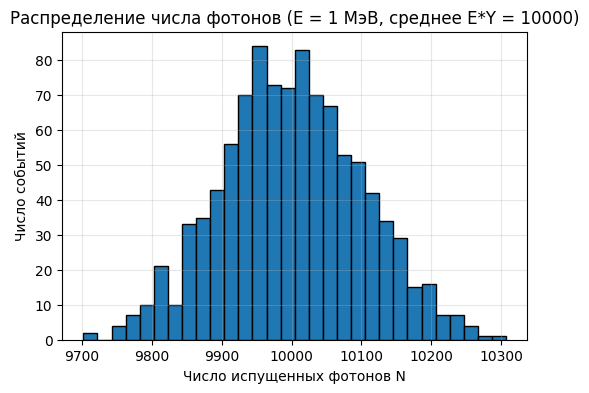

In [2]:
source = Source(Y=10000)

# Проверим генератор по 1 фотону (возьмем первые 3 фотона через next)
gen_single = source.generate_photons_single(E=1.0)
print("Первые 2 фотона из поштучного генератора:")
print(next(gen_single))
print(next(gen_single))

# Проверим генератор пачками по 100 фотонов для одного события с E = 1 МэВ
batches = list(source.generate_photons_batch(E=1.0, batch_size=100))
total_photons = sum(len(batch) for batch in batches)

print(f"\nСобытие E = 1 МэВ:")
print(f"Всего выдано пачек: {len(batches)}")
print(f"Размер первой пачки: {batches[0].shape}")
print(f"Размер последней пачки (остаток): {batches[-1].shape}")
print(f"Суммарное число фотонов в событии: {total_photons}")

# Проверим распределение Пуассона для числа фотонов (на 1000 событиях)
photon_counts = [
    sum(len(batch) for batch in source.generate_photons_batch(E=1.0, batch_size=100))
    for _ in range(1000)
]

plt.figure(figsize=(6, 4))
plt.hist(photon_counts, bins=30, edgecolor='black')
plt.xlabel('Число испущенных фотонов N')
plt.ylabel('Число событий')
plt.title('Распределение числа фотонов (E = 1 МэВ, среднее E*Y = 10000)')
plt.grid(alpha=0.3)
plt.show()